### 1. Importing libraries


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

### 2. Reading File

In [2]:
data = pd.read_csv(r'E:\clone\LatentHealth\data\cleaned_data.csv')

In [3]:
df_0 = data[data["diabetes"] == 0].sample(n=4000, random_state=42)
df_1 = data[data["diabetes"] == 1].sample(n=4000, random_state=42)
df = pd.concat([df_0, df_1])

### 3. virtualization

#### Alcohol Consumption Distribution by Diabetes Status

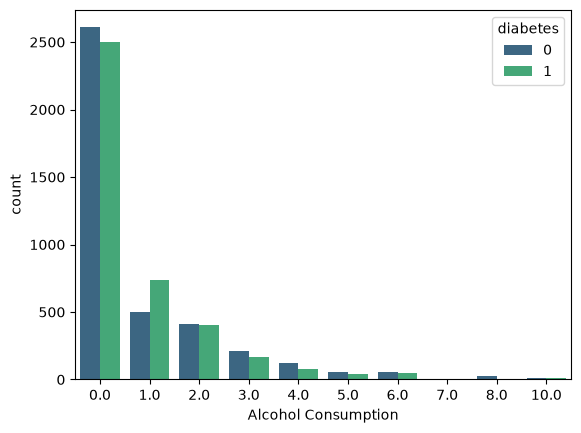

In [4]:
# Seeing the distribution of diabetes across alcohol consumption groups
sns.countplot(x=df['alcohol_use'], hue=df['diabetes'], palette='viridis')
plt.xlabel('Alcohol Consumption')
plt.show()

* Compares alcohol consumption patterns across diabetic and non-diabetic cohorts to investigate lifestyle risk factors.

In [5]:
print(df['alcohol_use'].value_counts())

alcohol_use
0.0     5112
1.0     1239
2.0      818
3.0      380
4.0      202
6.0      100
5.0       94
8.0       29
10.0      21
7.0        5
Name: count, dtype: int64


#### Diabetes Prevalence by Daily Sleep Duration (Percentage)

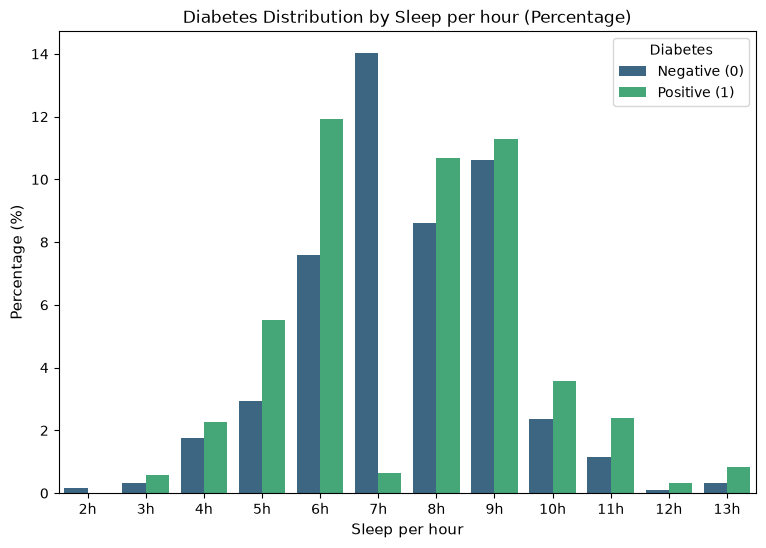

In [ ]:
plt.figure(figsize=(9, 6))
sns.countplot(
    x=df['SLD010H'],
    hue=df['diabetes'],
    palette='viridis',
    stat="percent"
)

plt.title('Diabetes Distribution by Sleep per hour (Percentage)', fontsize=12)
plt.xlabel('Sleep per hour', fontsize=11)
plt.ylabel('Percentage (%)', fontsize=11)

sleep_hours = list(range(2, 14))
plt.xticks(
    ticks=range(len(sleep_hours)),
    labels=[f'{h}h' for h in sleep_hours]
    )

plt.legend(title='Diabetes', labels=['Negative (0)', 'Positive (1)'])

plt.show()

* Analyzes the relationship between average sleep hours and diabetes risk, showing percentage distributions per sleep tier.

#### Diabetes Distribution Across Smoking Habits

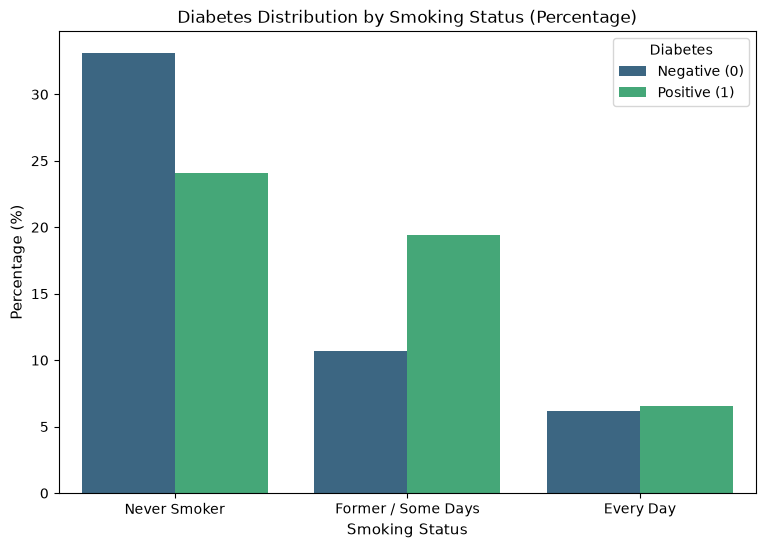

In [8]:
df_plot = df.copy()

smoking_labels = {0: 'Never Smoker', 1: 'Former / Some Days', 2: 'Every Day'}
df_plot['smoking_text'] = df_plot['smoking_status'].map(smoking_labels)

plt.figure(figsize=(9, 6))
sns.countplot(
    data=df_plot,
    x='smoking_text',
    hue='diabetes',
    palette='viridis',
    stat='percent',
)

plt.title('Diabetes Distribution by Smoking Status (Percentage)', fontsize=12)
plt.xlabel('Smoking Status', fontsize=11)
plt.ylabel('Percentage (%)', fontsize=11)

plt.legend(title='Diabetes', labels=['Negative (0)', 'Positive (1)'])

plt.show()

* Evaluates smoking categories (Never, Former/Some Days, Every Day) against diabetes status to observe behavioral correlations.

#### Impact of Physical Activity on Diabetes Prevalence

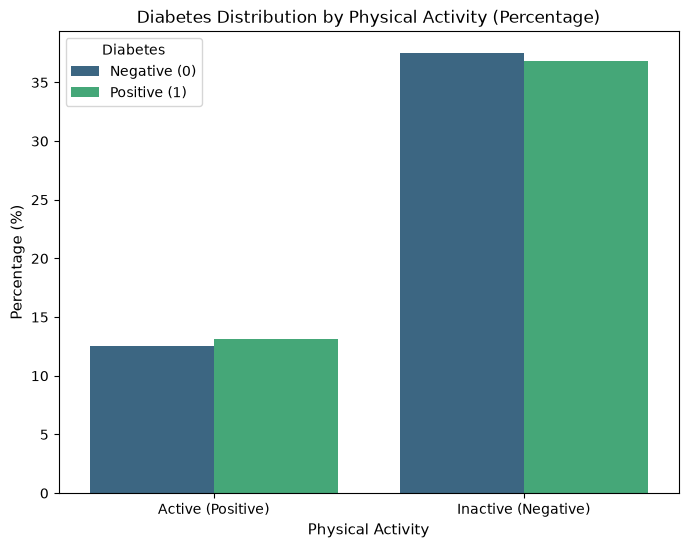

In [9]:
activity_labels = {0: 'Inactive (Negative)', 1: 'Active (Positive)'}
df_plot['activity_text'] = df_plot['physically_active'].map(activity_labels)

plt.figure(figsize=(8, 6))
sns.countplot(
    data=df_plot,
    x='activity_text',
    hue='diabetes',
    palette='viridis',
    stat='percent',
)
plt.title(
    'Diabetes Distribution by Physical Activity (Percentage)', fontsize=12
)
plt.xlabel('Physical Activity', fontsize=11)
plt.ylabel('Percentage (%)', fontsize=11)

plt.legend(title='Diabetes', labels=['Negative (0)', 'Positive (1)'])
plt.show()

* Contrasts active individuals versus inactive ones, clearly demonstrating the protective effect of regular physical activity against diabetes.

#### Scatter Plot of Weight vs. Height Segmented by Diabetes Status

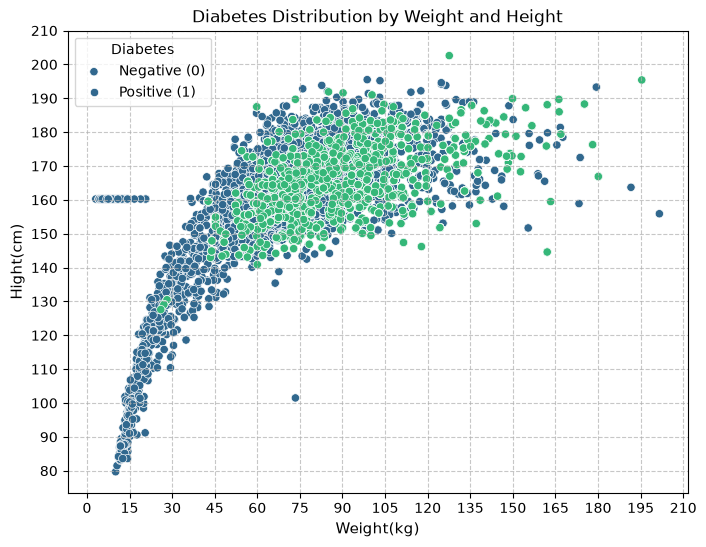

In [20]:
plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=df,
    x='BMXWT',
    y='BMXHT',
    hue='diabetes',
    palette='viridis'
)

plt.title('Diabetes Distribution by Weight and Height', fontsize=12)
plt.xlabel('Weight(kg)', fontsize=11)
plt.ylabel('Hight(cm)', fontsize=11)

plt.xticks(range(0, 211, 15))
plt.yticks(range(80, 211, 10))

plt.legend(title='Diabetes', labels=['Negative (0)', 'Positive (1)'])
plt.grid(linestyle='--', alpha=0.7)
plt.show()

* Examines anthropometric measurements (weight and height) across patient cohorts, highlighting physical clustering.

#### BMI Distribution Comparison: Diabetic vs. Non-Diabetic

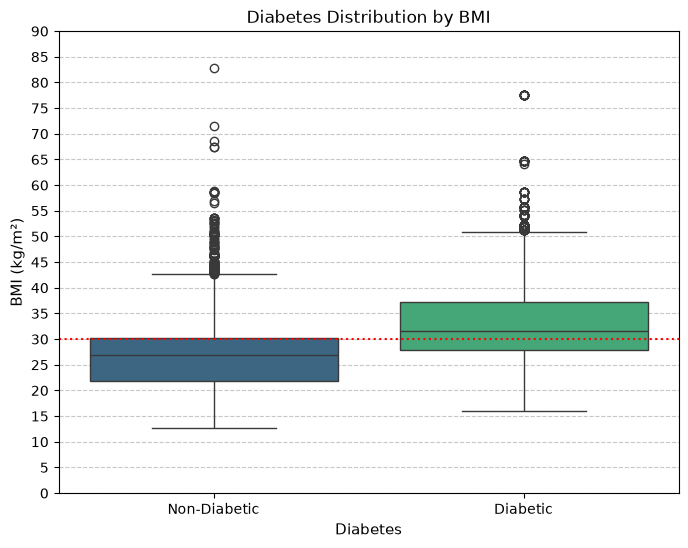

In [33]:
diabete_labels = {0: 'Non-Diabetic', 1: 'Diabetic'}
df_plot['diabetes_status'] = df_plot['diabetes'].map(diabete_labels)

plt.figure(figsize=(8, 6))
sns.boxplot(
    data=df_plot,
    x='diabetes_status',
    y='BMXBMI',
    palette='viridis'
)

plt.title('Diabetes Distribution by BMI', fontsize=12)
plt.xlabel('Diabetes', fontsize=11)
plt.ylabel('BMI (kg/m²)', fontsize=11)

plt.yticks(range(0, 91, 5))

plt.axhline(30, color='red', linestyle=':', linewidth=1.5, label='Obesity Threshold (BMI = 30)')

plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

* Box plot visualization demonstrating higher median BMI and interquartile ranges in the diabetes-positive group.

#### Glycohemoglobin (HbA1c) Levels Across Diabetes Status

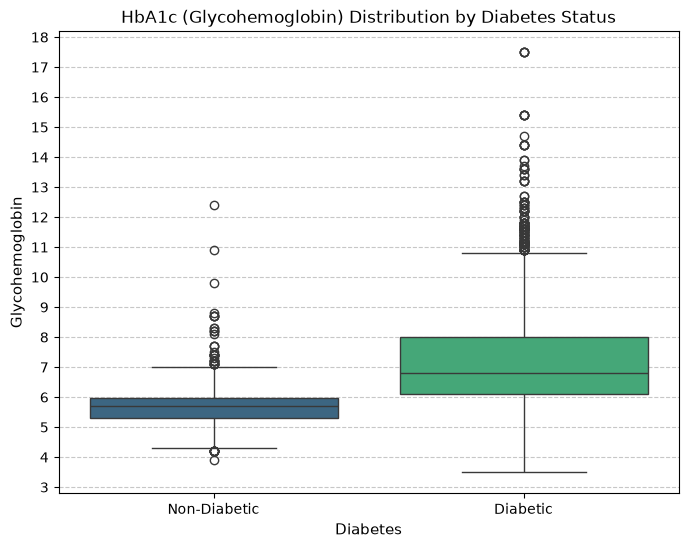

In [32]:
diabete_labels = {0: 'Non-Diabetic', 1: 'Diabetic'}
df_plot['diabetes_status'] = df_plot['diabetes'].map(diabete_labels)

plt.figure(figsize=(8, 6))
sns.boxplot(
    data=df_plot,
    x='diabetes_status',
    y='LBXGH',
    palette='viridis'
)

plt.title('HbA1c (Glycohemoglobin) Distribution by Diabetes Status', fontsize=12)
plt.xlabel('Diabetes', fontsize=11)
plt.ylabel('Glycohemoglobin', fontsize=11)

plt.yticks(range(3, 19, 1))

plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

* HbA1c biomarker distribution displaying a clear upward shift and median crossing of the standard diagnostic threshold (6.5%) in the diabetic cohort.

#### Diabetes Prevalence Stratified by Household Income Levels

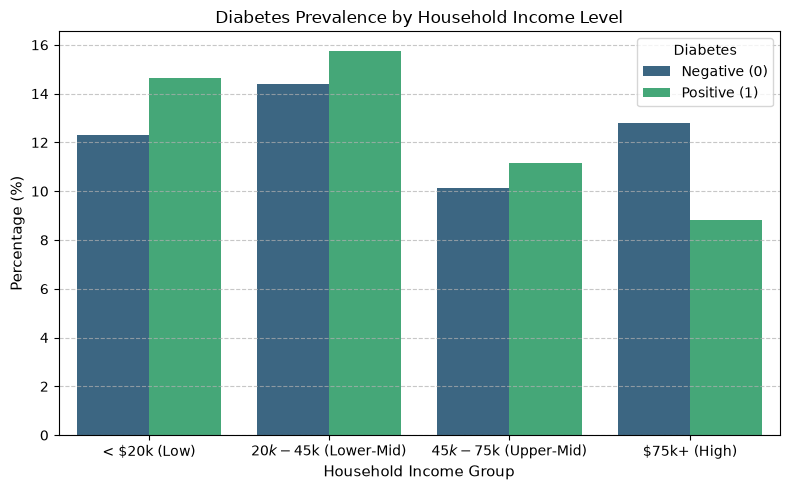

In [34]:
income_map = {
    1: '< $20k (Low)',
    2: '< $20k (Low)',
    3: '< $20k (Low)',
    4: '< $20k (Low)',
    13: '< $20k (Low)',
    5: '$20k - $45k (Lower-Mid)',
    6: '$20k - $45k (Lower-Mid)',
    7: '$20k - $45k (Lower-Mid)',
    8: '$45k - $75k (Upper-Mid)',
    9: '$45k - $75k (Upper-Mid)',
    10: '$45k - $75k (Upper-Mid)',
    12: '$45k - $75k (Upper-Mid)',
    14: '$75k+ (High)',
    15: '$75k+ (High)',
}

order = [
    '< $20k (Low)',
    '$20k - $45k (Lower-Mid)',
    '$45k - $75k (Upper-Mid)',
    '$75k+ (High)',
]

plot_df = df[df['INDHHIN2'].isin(income_map.keys())].copy()
plot_df['income_group'] = plot_df['INDHHIN2'].map(income_map)

plt.figure(figsize=(8, 5))
sns.countplot(
    data=plot_df,
    x='income_group',
    hue='diabetes',
    order=order,
    palette='viridis',
    stat='percent',
)

plt.title('Diabetes Prevalence by Household Income Level', fontsize=12)
plt.xlabel('Household Income Group', fontsize=11)
plt.ylabel('Percentage (%)', fontsize=11)

plt.legend(title='Diabetes', labels=['Negative (0)', 'Positive (1)'])
plt.tight_layout()
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

* Investigates socioeconomic disparities by grouping annual household income tiers from low to high.

#### Triglyceride vs. Total Cholesterol Levels by Diabetes Status

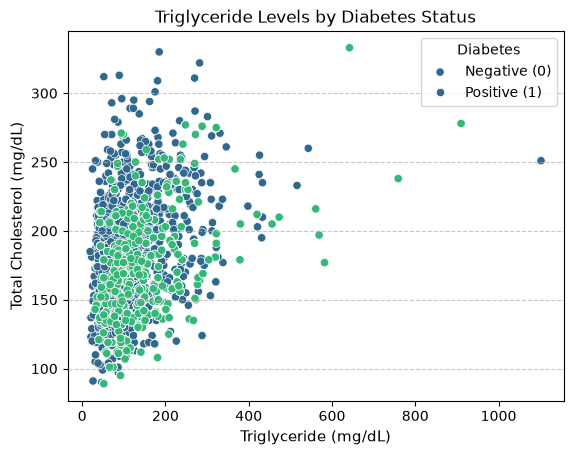

In [35]:
changed_df = df[(df['LBXTR'] <= 1500) & (df['LBXTC'] <= 400)]
imputed_val = changed_df['LBXTR'].mode()[0]

filtered_df = changed_df[changed_df['LBXTR'] != imputed_val]

sns.scatterplot(
    data=filtered_df,
    x='LBXTR',
    y='LBXTC',
    hue='diabetes',
    palette='viridis'
)

plt.title('Triglyceride Levels by Diabetes Status', fontsize=12)
plt.xlabel('Triglyceride (mg/dL)', fontsize=11)
plt.ylabel('Total Cholesterol (mg/dL)', fontsize=11)

plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend(title='Diabetes', labels=['Negative (0)', 'Positive (1)'])
plt.show()

* Scatter plot with clinical cutoff thresholds (
>
150
 mg/dL
>150 mg/dL
 for triglycerides, 
>
200
 mg/dL
>200 mg/dL
 for total cholesterol) displaying lipid profile risk factors.